In [8]:
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
labels = ["Airplane", "Automobile", "Bird", "Cat", "Deer", "Dog", "Frog", "Horse", "Ship", "Truck"]

In [3]:
# cifar10 데이터 로드
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

In [4]:
x_train.shape, x_test.shape

((50000, 32, 32, 3), (10000, 32, 32, 3))

In [5]:
np.unique(y_train, return_counts = True)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8),
 array([5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000],
       dtype=int64))

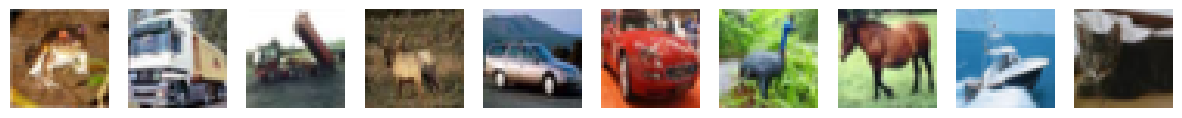

In [9]:
fig, axs = plt.subplots(1, 10, figsize = (15, 15))

for i in range(10):
    axs[i].imshow(x_train[i])
    axs[i].axis("off")
plt.show()

In [13]:
[labels[i] for i in y_train[:10, 0]]

['Frog',
 'Truck',
 'Truck',
 'Deer',
 'Automobile',
 'Automobile',
 'Bird',
 'Horse',
 'Ship',
 'Cat']

In [15]:
x_train.min(), x_train.max()

(0, 255)

In [16]:
scaled_train = x_train / 255
scaled_test = x_test / 255

In [17]:
scaled_sub, scaled_val, y_sub, y_val = train_test_split(scaled_train, y_train, test_size = 0.2,
                                                        stratify = y_train, random_state = 26)

In [18]:
scaled_sub.shape, scaled_val.shape, scaled_test.shape

((40000, 32, 32, 3), (10000, 32, 32, 3), (10000, 32, 32, 3))

In [19]:
y_sub.shape

(40000, 1)

# 모델 설계

## 배치 정규화(Batch Normalization)

- 의의
    - 딥러닝 모델의 학습을 안정화하고 속도를 향상시키기 위해 사용하는 기법
 
    - 각 층에서 입력 데이터의 분포를 정규화하여 학습 과정을 개선
 
- 목적
    - 내부 공변량 변화 감소
        - 신경망의 각 층이 학습되는 동안 입력데이터의 분포가 지속적으로 변화하는 문제를 완화
     
        - 각 층이 안정적으로 학습할 수 있도록 하는 역할
     
    - 학습 속도 향상
        - 정규화된 입력으로 더 높은 학습률을 사용할 수 있게 하여 학습 속도를 높일 수 있음
     
    - 초기화에 대한 민감도 감소
        - 가중치 초기화에 덜 민감하게 만들어 초기화 방법의 선택에 따른 영향을 줄임
     
    - 규제
        - 과대적합을 방지
     
- 작동 원리
    - 주로 신경망의 각 층에서 활성화 함수 입력 전에 적용
    1. 미니배치 통계 계산
        - 미니배치 내의 각 특성에 대해 평균과 분산을 계산
          
    2. 정규화
        - 각 입력 특성을 정규화하여 평균이 0이고 분산이 1인 값으로 변환
          
    3. 스케일링 및 이동
        - 정규화된 값에 학습 가능한 파라미터 감마와 베타를 적용하여 출력값을 조정
        - 모델이 필요에 따라 데이터를 재조정하는 역할
      
- 배치 정규화의 적용 예시
    - 밀집층 이후 활성화 함수 적용 전
    - 합성곱층 연산 후, 활성화 함수 적용 전

In [25]:
model = keras.Sequential()

model.add(keras.Input(shape = (32, 32, 3)))

model.add(keras.layers.Conv2D(64, 4, padding = "same"))
model.add(keras.layers.BatchNormalization())
model.add(keras.layers.Activation(keras.activations.relu))
model.add(keras.layers.Dropout(0.3))
model.add(keras.layers.Conv2D(64, 4, padding = "same"))
model.add(keras.layers.BatchNormalization())
model.add(keras.layers.Activation(keras.activations.relu))
model.add(keras.layers.MaxPool2D(2))
model.add(keras.layers.Dropout(0.3))

model.add(keras.layers.Conv2D(128, 4, padding = "same"))
model.add(keras.layers.BatchNormalization())
model.add(keras.layers.Activation(keras.activations.relu))
model.add(keras.layers.Dropout(0.3))
model.add(keras.layers.Conv2D(128, 4, padding = "same"))
model.add(keras.layers.BatchNormalization())
model.add(keras.layers.Activation(keras.activations.relu))
model.add(keras.layers.MaxPool2D(2))
model.add(keras.layers.Dropout(0.3))

model.add(keras.layers.Conv2D(128, 4, padding = "same"))
model.add(keras.layers.BatchNormalization())
model.add(keras.layers.Activation(keras.activations.relu))
model.add(keras.layers.Dropout(0.3))
model.add(keras.layers.Conv2D(128, 4, padding = "same"))
model.add(keras.layers.BatchNormalization())
model.add(keras.layers.Activation(keras.activations.relu))
model.add(keras.layers.MaxPool2D(2))
model.add(keras.layers.Dropout(0.3))

model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(256))
model.add(keras.layers.BatchNormalization())
model.add(keras.layers.Activation(keras.activations.relu))
model.add(keras.layers.Dropout(0.3))

model.add(keras.layers.Dense(10, activation = "softmax"))

In [26]:
model.compile(loss = "sparse_categorical_crossentropy", optimizer = "adam", metrics = ["accuracy"])

In [27]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)                    │ (None, 32, 32, 64)          │           3,136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 32, 32, 64)          │          65,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 32, 32, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 16, 16, 128)         │         131,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 16, 16, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 16, 16, 128)         │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 16, 16, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 8, 8, 128)           │         262,272 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 1,517,450 (5.79 MB)

 Trainable params: 1,515,658 (5.78 MB)

 Non-trainable params: 1,792 (7.00 KB)

In [28]:
es_cb = keras.callbacks.EarlyStopping(patience = 4, restore_best_weights = True)

In [29]:
history = model.fit(scaled_sub, y_sub, epochs = 100, validation_data = (scaled_val, y_val),
                    callbacks = [es_cb], batch_size = 64)

Epoch 1/100
186/625 ━━━━━━━━━━━━━━━━━━━━ 3:30 479ms/step - accuracy: 0.2430 - loss: 2.1921

KeyboardInterrupt: 